# TP 2 — Transport de probabilités et simulation


## Sur papier — Dimensionnement d’une station-relais

Une entreprise exploite une station-relais de télécommunications dans une zone isolée. En cas de coupure du réseau électrique, la station doit continuer à fonctionner grâce à des batteries de secours.

On suppose que la puissance consommée reste constante pendant chaque coupure. L’énergie nécessaire (en kWh) est alors égale au produit de la puissance consommée (en kW) par la durée de la coupure (en heures) :

$$
\text{Énergie (kWh)}
=\text{Puissance (kW)}\times\text{Durée (h)}.
$$

Afin d’anticiper les besoins énergétiques de la station, l’entreprise dispose de données relatives à 200 coupures électriques historiques, observées sur des sites comparables.

L’objectif est d’exploiter ces données pour prévoir les besoins futurs en énergie et d’aider l’entreprise à prendre une décision concernant le dimensionnement des batteries de secours.

Pour cette étude, on suppose que les fréquences observées dans les données historiques sont représentatives des situations futures.

| Régime | Puissance | 30 min | 60 min | 90 min |
|:---|---:|---:|---:|---:|
| Normal | 8 kW | 50 | 40 | 20 |
| Forte charge | 16 kW | 40 | 30 | 20 |

### Questions

1. **Modéliser l’expérience.** Proposer un espace probabilisé $(\Omega,\mathcal A,\mathbb P_\Omega)$ permettant de modéliser le profil possible d’une coupure électrique.

2. **Anticiper les besoins énergétiques.** Le responsable technique veut connaître les différentes quantités d’énergie nécessaires lors d’une coupure, ainsi que leurs probabilités. Construire une application $X$ adaptée : préciser son domaine, son espace mesurable d’arrivée, et déterminer sa fonction de masse.

3. **Prévoir le stock de batteries.** Le fournisseur propose des modules de batterie de capacité utile 6 kWh chacun.

   À partir du seul besoin énergétique, proposer une règle donnant le nombre nécessaire de modules permettant de couvrir une coupure. Définir l’application correspondante sur l’espace d’arrivée de $X$ et déterminer la fonction de masse du nombre de modules nécessaires.

4. **Choisir l’installation.** L’entreprise souhaite installer le plus petit nombre de modules qui couvre les besoins pendant au moins 90 % des coupures. Combien faut-il de modules ?

5. **Contrôler une affirmation.** Pour l’installation répondant à l’objectif de couverture de 90 %, calculer d’abord la probabilité que le besoin énergétique soit couvert sachant que la station fonctionne en forte charge.

   Un ingénieur affirme ensuite : « Si l’installation couvre 90 % des coupures, elle couvre nécessairement au moins 90 % de celles qui surviennent en période de forte charge. » Cette affirmation est-elle exacte ? Justifier à partir du calcul précédent.

6. **Application à un village de montagne.** La commune fictive de Mont-Roc souhaite équiper sa station-relais. Son programme de secours vise les coupures nécessitant une intervention sur la ligne électrique de montagne : dans ce scénario, ce sont les coupures d’au moins 60 minutes. Les coupures plus courtes sont prises en charge par un dispositif distinct.

   Parmi les coupures pertinentes pour Mont-Roc, déterminer les fonctions de masse du besoin énergétique et du nombre minimal de modules nécessaires. Conseiller le plus petit nombre de modules permettant de couvrir au moins 90 % de ces coupures.


Voir le corrigé du TD2 exo2.

## Données du modèle — six issues, six masses

Une coupure électrique est décrite par son **régime** et sa **durée**. Les issues sont, dans cet ordre :

$$\Omega=\{(N,30),(N,60),(N,90),(F,30),(F,60),(F,90)\}.$$

$N$ signifie **normal** (8 kW), $F$ signifie **forte charge** (16 kW), et les durées sont en **minutes**. Chaque issue a pour probabilité sa fréquence parmi les 200 coupures historiques.

| Régime | 30 min | 60 min | 90 min |
|:--|--:|--:|--:|
| Normal (8 kW) | 50 | 40 | 20 |
| Forte charge (16 kW) | 40 | 30 | 20 |

**Important :** l'univers possède **six issues**, pas 200 issues équiprobables. Les 200 observations historiques ne servent qu'à déterminer les masses initiales.

In [2]:
# Cellule de préparation : à exécuter sans la modifier.
import numpy as np
import matplotlib.pyplot as plt

profils = np.array(["N-30", "N-60", "N-90", "F-30", "F-60", "F-90"])
effectifs = np.array([50, 40, 20, 40, 30, 20])
p_omega = effectifs / np.sum(effectifs)

puissances = np.array([8, 8, 8, 16, 16, 16])  # en kW
durees_min = np.array([30, 60, 90, 30, 60, 90])

print("Profils :", profils)
print("Masses de départ :", p_omega)
print("Somme des masses :", np.sum(p_omega))

Profils : ['N-30' 'N-60' 'N-90' 'F-30' 'F-60' 'F-90']
Masses de départ : [0.25 0.2  0.1  0.2  0.15 0.1 ]
Somme des masses : 1.0


---
## Étape 1 / 4 — Échantillonner dans $\Omega$

### M1 — Examiner la loi théorique

Quel est le **profil le plus probable** ? Les six profils sont-ils équiprobables ?

**Aide — `np.argmax` :** renvoie l'indice du plus grand élément d'un tableau. `help(np.argmax)`.

In [3]:
indice_max = np.argmax(p_omega)
print("Indice du profil le plus probable =", indice_max)
print("Profil le plus probable =", profils[indice_max])
print("Sa masse =", p_omega[indice_max])

Indice du profil le plus probable = 0
Profil le plus probable = N-30
Sa masse = 0.25


> **Réponse / interprétation :** Le profil **N-30** a la masse $50/200=0{,}25$, la plus élevée. Les six profils **ne sont pas équiprobables**.

### M2 — Produire 1 000 tirages pondérés

**Nouvelle commande — `rng.choice`** : `rng.choice(a, size=n, p=poids)` tire `n` éléments parmi `a`, avec remise par défaut, en utilisant les probabilités `poids`. Ici, les entiers `0,1,…,5` **codent** les six issues ; ce ne sont ni les énergies ni les durées.

Exemple : `rng.choice(3, size=5, p=[0.2, 0.3, 0.5])`.

Aide : `help(rng.choice)` ou `rng.choice?`. [Documentation officielle NumPy](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html).

**À faire.** Tirer 1 000 profils selon `p_omega`, afficher les dix premiers. Quelle est la différence entre les 200 observations historiques et ces 1 000 tirages simulés ?

In [4]:
rng = np.random.default_rng(2026)
indices = rng.choice(6, size=1000, p=p_omega)
print("Premiers codes :", indices[:10])
print("Premiers profils :", profils[indices[:10]])

Premiers codes : [0 3 2 1 1 4 5 0 3 1]
Premiers profils : ['N-30' 'F-30' 'N-90' 'N-60' 'N-60' 'F-60' 'F-90' 'N-30' 'F-30' 'N-60']


> **Réponse / interprétation :** Les **200 observations historiques** ont servi à estimer les masses du modèle. Les **1 000 tirages simulés** sont un nouvel échantillon aléatoire obtenu *avec remise* selon ces masses. Chaque tirage est une **issue de $\Omega$** (codée par un entier).

### M3 — Compter les profils simulés

**Nouvelle commande — `np.bincount`.** Elle compte les occurrences des codes entiers. L'argument `minlength=6` conserve les six catégories même si l'une n'a pas été tirée.

```python
np.bincount(np.array([0, 2, 2, 4]), minlength=6)
# array([1, 0, 2, 0, 1, 0, 0])
```

Aide : `help(np.bincount)`.

**À faire.** Calculer `freq_omega`, le tableau des **fréquences empiriques**, puis le comparer à `p_omega`.

In [5]:
freq_omega = np.bincount(indices, minlength=6) / len(indices)
print("Théorie   :", p_omega)
print("Empirique :", freq_omega)
print("Somme des fréquences empiriques :", np.sum(freq_omega))

Théorie   : [0.25 0.2  0.1  0.2  0.15 0.1 ]
Empirique : [0.223 0.194 0.099 0.215 0.155 0.114]
Somme des fréquences empiriques : 1.0


### M4 — Deux diagrammes `stem` superposés

**Rappel — `plt.stem`.** `plt.stem(abscisses, masses, ...)` trace des bâtons fins. On décale légèrement les abscisses pour distinguer théorie et simulation : `positions - 0.08` et `positions + 0.08`.

- `linefmt` : style des tiges ; `markerfmt` : style des points.
- `plt.xticks(positions, profils)` : étiquettes des six positions.
- `plt.legend()` : légende ; `plt.show()` : affichage.

Aide : `help(plt.stem)`. [Documentation Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.stem.html).

**À faire.** Superposer les **masses théoriques sur $\Omega$** et les **fréquences simulées** sur un même graphique.

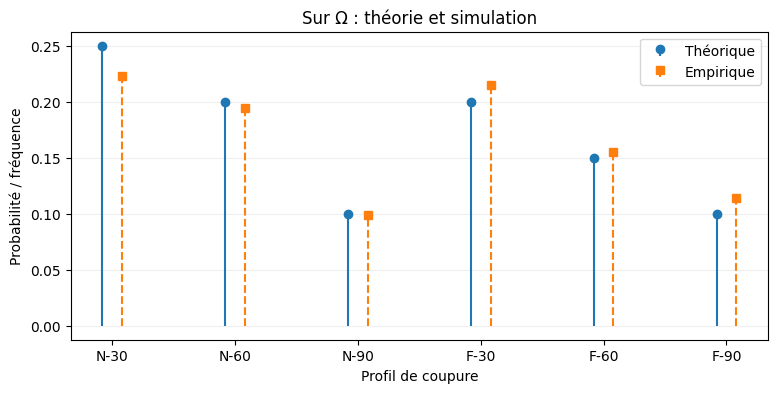

In [5]:
positions = np.arange(len(profils))
plt.figure(figsize=(9, 4))
plt.stem(positions - 0.08, p_omega,
         linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Théorique")
plt.stem(positions + 0.08, freq_omega,
         linefmt="C1--", markerfmt="C1s", basefmt=" ", label="Empirique")
plt.xticks(positions, profils)
plt.xlabel("Profil de coupure")
plt.ylabel("Probabilité / fréquence")
plt.title("Sur Ω : théorie et simulation")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

### M5 — Quel est l'effet de la taille de l'échantillon ?

Simuler séparément **50** et **10 000** issues. Comparer les fréquences empiriques aux masses de `p_omega` (par exemple avec le plus grand écart absolu). Les écarts sont-ils toujours nuls ?

**Conserver impérativement `indices` (1 000 tirages) pour M6 à M14.** Ne pas le remplacer par un autre échantillon.

**Aide — `np.abs` et `np.max` :** `np.abs(a-b)` calcule les écarts absolus terme à terme ; `np.max(...)` en donne le plus grand. `help(np.abs)` et `help(np.max)`.

In [6]:
indices_50 = rng.choice(6, size=50, p=p_omega)
indices_10000 = rng.choice(6, size=10000, p=p_omega)
freq_50 = np.bincount(indices_50, minlength=6) / len(indices_50)
freq_10000 = np.bincount(indices_10000, minlength=6) / len(indices_10000)
print("Écart maximal avec 50 tirages :", np.max(np.abs(freq_50 - p_omega)))
print("Écart maximal avec 10000 tirages :", np.max(np.abs(freq_10000 - p_omega)))

Écart maximal avec 50 tirages : 0.08000000000000002
Écart maximal avec 10000 tirages : 0.006699999999999984


> **Réponse / interprétation :** Les fréquences empiriques ne coïncident généralement **pas exactement** avec les masses théoriques. En augmentant la taille de l’échantillon, elles tendent à s’en rapprocher, sans garantie d’un écart strictement décroissant à chaque expérience.

---
## Étape 2 / 4 — Transporter **le même échantillon** par $X$

Soit $X:\Omega\to\mathbb R$ la quantité **d'énergie nécessaire** (en kWh) :

$$X(\omega)=\text{Puissance}(\omega)\times \frac{\text{Durée en minutes}(\omega)}{60}.$$

### M6 — Construire les énergies des 1 000 profils simulés

**Rappel — calcul vectorisé et indexation.** `puissances * durees_min / 60` effectue le calcul terme à terme ; `X_profils[indices]` applique $X$ **aux issues déjà tirées**.

**À faire.** Construire `X_profils` (six valeurs), puis `X_tirages` (mille valeurs). **Ne pas appeler à nouveau `rng.choice` !**

In [11]:
X_val = puissances * durees_min / 60       
X_profils = np.unique(X_val)       # Énergies associées aux 6 issues Omega.
X_tirages = puissances[indices] * durees_min[indices] / 60        # Énergies des 1000 mêmes tirages.
print("Énergies par profil :", X_profils)
print("Premiers profils tirés :", profils[indices[:8]])
print("Énergies associées :", X_tirages[:8])

Énergies par profil : [ 4.  8. 12. 16. 24.]
Premiers profils tirés : ['N-30' 'F-30' 'N-90' 'N-60' 'N-60' 'F-60' 'F-90' 'N-30']
Énergies associées : [ 4.  8. 12.  8.  8. 16. 24.  4.]


### M7 — Construire $p_X$ et les fréquences empiriques de $X$

**Rappel — `np.unique` et masques booléens.**

```python
a = np.array([4, 8, 8, 4])
np.unique(a)       # array([4, 8])
np.mean(a == 8)    # 0.5
```

La forme `[calcul(x) for x in valeurs]` permet de répéter un calcul pour chaque valeur de `valeurs` (syntaxe Python : *compréhension de liste*). [Tutoriel Python — compréhensions de listes](https://docs.python.org/fr/3/tutorial/datastructures.html#list-comprehensions).

Aide : `help(np.unique)`, `help(np.sum)`, `help(np.mean)` et `help(np.array)`.

**À faire.** Pour chaque énergie $x$, calculer sa fréquence parmi les énergies simulées, la comparer à la valeur théorique.

In [15]:
p_X = np.array([np.sum(p_omega[X_val == x]) for x in X_profils])
freq_X = np.array([np.mean(X_tirages == x) for x in X_profils])
print("Énergies possibles :", X_profils)
print("p_X (théorie) :", p_X)
print("Fréquences de X :", freq_X)
assert np.isclose(p_X.sum(), 1)
assert np.allclose(p_X, [0.25, 0.4, 0.1, 0.15, 0.1])

Énergies possibles : [ 4.  8. 12. 16. 24.]
p_X (théorie) : [0.25 0.4  0.1  0.15 0.1 ]
Fréquences de X : [0.223 0.409 0.099 0.155 0.114]


### M8 — Superposer les lois théorique et empirique de $X$

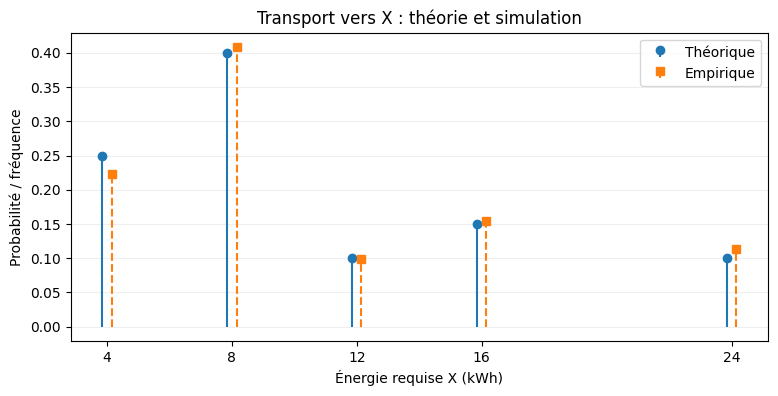

In [9]:
plt.figure(figsize=(9, 4))
plt.stem(support_X - 0.15, p_X,
         linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Théorique")
plt.stem(support_X + 0.15, freq_X,
         linefmt="C1--", markerfmt="C1s", basefmt=" ", label="Empirique")
plt.xticks(support_X)
plt.xlabel("Énergie requise X (kWh)")
plt.ylabel("Probabilité / fréquence")
plt.title("Transport vers X : théorie et simulation")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()